<a href="https://colab.research.google.com/github/julpontanares-byte/projects-portfolio/blob/main/LA2_Pontanares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Dependencies & Kaggle Dataset Setup**

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d muratkokludataset/rice-image-dataset

DATASET_DIR = "./data/Rice_Image_Dataset"
CLASSES = ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']

# Check if the dataset directory already exists before unzipping
if not os.path.exists(DATASET_DIR):
    print("Unzipping dataset...")
    !unzip -q rice-image-dataset.zip -d ./data
else:
    print("Dataset directory already exists. Skipping unzip.")

Dataset URL: https://www.kaggle.com/datasets/muratkokludataset/rice-image-dataset
License(s): CC0-1.0
rice-image-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset directory already exists. Skipping unzip.


## **Dataset Splitting**: 70% Training, 15% Validation, 15% Testing

In [ ]:
def load_and_split_dataset(img_size=(64, 64), batch_size=64):
    """
    Loads images and creates clean, deterministic 70/15/15 splits.
    """
    # Load 70% training subset (52,500 images)
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        validation_split=0.30,
        subset="training",
        seed=42,
        image_size=img_size,
        batch_size=batch_size
    )

    # Load 30% remaining subset for validation and testing (22,500 images)
    raw_val_test_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        validation_split=0.30,
        subset="validation",
        seed=42,
        image_size=img_size,
        batch_size=batch_size
    )

    # Calculate total batches in the 30% split and divide equally (175 batches each)
    total_val_batches = tf.data.experimental.cardinality(raw_val_test_ds).numpy()
    val_batches = total_val_batches // 2

    # Split dataset cleanly at batch level
    val_ds = raw_val_test_ds.take(val_batches)
    test_ds = raw_val_test_ds.skip(val_batches)

    # Rescale pixel values from [0, 255] to [0, 1]
    rescale_layer = layers.Rescaling(1./255)

    train_ds = train_ds.map(lambda x, y: (rescale_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(lambda x, y: (rescale_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(lambda x, y: (rescale_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)

    # Apply prefetching for optimal performance without iterator state issues
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

    return train_ds, val_ds, test_ds

In [ ]:
# Note this is only for splitting checking
import tensorflow as tf

def print_dataset_counts(train_ds, val_ds, test_ds, batch_size=64):
    # Calculate exact batch counts using cardinality
    train_batches = tf.data.experimental.cardinality(train_ds).numpy()
    val_batches = tf.data.experimental.cardinality(val_ds).numpy()
    test_batches = tf.data.experimental.cardinality(test_ds).numpy()

    # Multiply batches by batch size to determine sample estimates
    num_train = train_batches * batch_size
    num_val = val_batches * batch_size
    num_test = test_batches * batch_size

    # Adjust for potential partial batches at the end of splits
    total_images = num_train + num_val + num_test

    print("=== DATASET SPLIT COUNT ===")
    print(f"Training Set:   ~{num_train:,} images (~{num_train/total_images:.2%}) [{train_batches} batches]")
    print(f"Validation Set: ~{num_val:,} images (~{num_val/total_images:.2%}) [{val_batches} batches]")
    print(f"Testing Set:    ~{num_test:,} images (~{num_test/total_images:.2%}) [{test_batches} batches]")
    print(f"Total Images:   ~{total_images:,} images (100.00%)")

# Define parameters consistent with the training section
img_height, img_width = 64, 64
batch_size = 64

# Load and split dataset
train_ds, val_ds, test_ds = load_and_split_dataset((img_height, img_width), batch_size)

# Execute fast batch checking
print_dataset_counts(train_ds, val_ds, test_ds, batch_size)

Found 75000 files belonging to 5 classes.
Using 52500 files for training.
Found 75000 files belonging to 5 classes.
Using 22500 files for validation.
=== DATASET SPLIT COUNT ===
Training Set:   ~52,544 images (~69.99%) [821 batches]
Validation Set: ~11,264 images (~15.00%) [176 batches]
Testing Set:    ~11,264 images (~15.00%) [176 batches]
Total Images:   ~75,072 images (100.00%)


# **Model Architecture:** Simple Neural Network

In [ ]:
def build_nn(input_shape=(64, 64, 3), num_classes=5):
    """
    Builds a Multilayer Perceptron without Convolution or Pooling layers.
    """
    model = models.Sequential([
        layers.Input(shape=input_shape),  # Changed input_shape= to shape=
        layers.Flatten(name="Flatten_Layer"),
        layers.Dense(128, activation='relu', name="Dense_Hidden_1"),
        layers.Dense(64, activation='relu', name="Dense_Hidden_2"),
        layers.Dense(num_classes, activation='softmax', name="Output_Layer")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

## Training

In [ ]:
img_height, img_width = 64, 64
batch_size = 64
epochs = 10

train_ds, val_ds, test_ds = load_and_split_dataset((img_height, img_width), batch_size)
model = build_nn(input_shape=(img_height, img_width, 3), num_classes=len(CLASSES))
model.summary()

# Train Model
start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
training_time_64 = time.time() - start_time

# Save the model in Keras format
os.makedirs("Models", exist_ok=True)
model.save("Models/rice_model.keras")
print("Model saved successfully in Models/rice_model.keras")

Found 75000 files belonging to 5 classes.
Using 52500 files for training.
Found 75000 files belonging to 5 classes.
Using 22500 files for validation.


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Flatten_Layer (Flatten)         │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden_1 (Dense)          │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,581,573 (6.03 MB)

 Trainable params: 1,581,573 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 0.9500 - loss: 0.1440 - val_accuracy: 0.9644 - val_loss: 0.1095
Epoch 2/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 73s 51ms/step - accuracy: 0.9713 - loss: 0.0829 - val_accuracy: 0.9774 - val_loss: 0.0672
Epoch 3/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9771 - loss: 0.0642 - val_accuracy: 0.9822 - val_loss: 0.0501
Epoch 4/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 44s 54ms/step - accuracy: 0.9809 - loss: 0.0570 - val_accuracy: 0.9798 - val_loss: 0.0559
Epoch 5/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - accuracy: 0.9830 - loss: 0.0489 - val_accuracy: 0.9830 - val_loss: 0.0488
Epoch 6/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 39s 48ms/step - accuracy: 0.9849 - loss: 0.0446 - val_accuracy: 0.9856 - val_loss: 0.0417
Epoch 7/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.9870 - loss: 0.0378 - val_accuracy: 0.9859 - val_loss: 0.0411
Epoch 8/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - accuracy: 0.9866 - loss: 0.0382 - 

## Plot Loss and Accuracy Curves

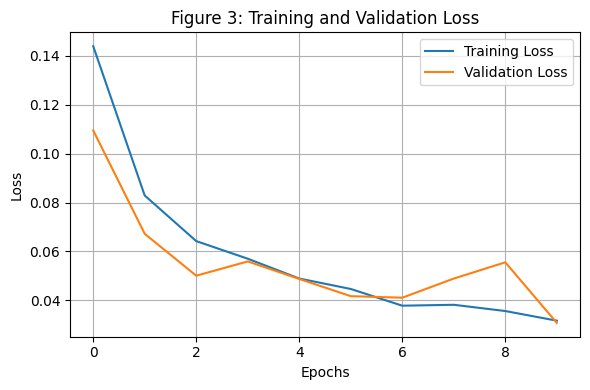

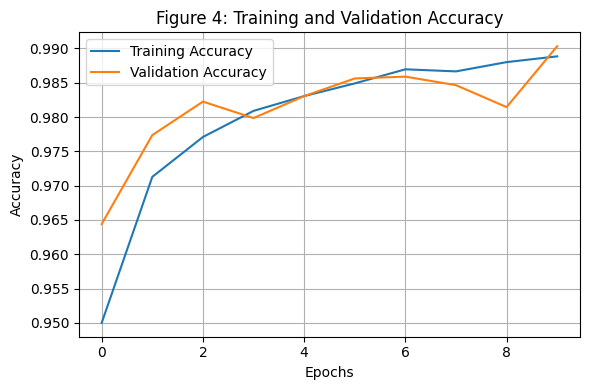

In [ ]:
# Create the target directory if it doesn't already exist
output_dir = 'Curves'
os.makedirs(output_dir, exist_ok=True)
# Loss Curve
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Figure 3: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Loss_curve.png'))
plt.show()

# Figure 4: Accuracy Curve
plt.figure(figsize=(6, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Figure 4: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Accuracy_curve.png'))
plt.show()

## Image Resolution Expirement

In [ ]:
resolutions = [(32, 32), (64, 64), (128, 128)]
exp_results = {}

for res in resolutions:
    print(f"\n--- Running Experiment for Resolution: {res[0]}x{res[1]} ---")

    t_ds, v_ds, te_ds = load_and_split_dataset(res, batch_size=64)
    exp_model = build_nn(input_shape=(res[0], res[1], 3))

    start_t = time.time()
    h = exp_model.fit(t_ds, validation_data=v_ds, epochs=10, verbose=1)
    elapsed_t = time.time() - start_t

    test_loss, test_acc = exp_model.evaluate(te_ds, verbose=0)
    train_acc = h.history['accuracy'][-1]
    val_acc = h.history['val_accuracy'][-1]

    exp_results[res] = {
        'input_features': res[0] * res[1] * 3,
        'params': exp_model.count_params(),
        'train_acc': train_acc,
        'val_acc': val_acc,
        'test_acc': test_acc,
        'time_sec': elapsed_t
    }

# Display Experiment Summary Table
print("\n=== EXPERIMENTAL RESULTS TABLE ===")
for res, res_data in exp_results.items():
    print(f"Resolution {res[0]}x{res[1]} | Features: {res_data['input_features']} | "
          f"Params: {res_data['params']:,} | Test Acc: {res_data['test_acc']:.4f} | "
          f"Time: {res_data['time_sec']:.2f}s")


--- Running Experiment for Resolution: 32x32 ---
Found 75000 files belonging to 5 classes.
Using 52500 files for training.
Found 75000 files belonging to 5 classes.
Using 22500 files for validation.
Epoch 1/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 27s 31ms/step - accuracy: 0.9487 - loss: 0.1507 - val_accuracy: 0.9650 - val_loss: 0.1007
Epoch 2/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 39s 30ms/step - accuracy: 0.9709 - loss: 0.0840 - val_accuracy: 0.9773 - val_loss: 0.0694
Epoch 3/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - accuracy: 0.9760 - loss: 0.0686 - val_accuracy: 0.9813 - val_loss: 0.0580
Epoch 4/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9791 - loss: 0.0603 - val_accuracy: 0.9781 - val_loss: 0.0620
Epoch 5/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 27s 33ms/step - accuracy: 0.9830 - loss: 0.0506 - val_accuracy: 0.9824 - val_loss: 0.0518
Epoch 6/10
821/821 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.9836 - loss: 0.0470 - val_accuracy: 0.9852 - val_loss: 0.0453
Epoch 7/10
821/821 ━

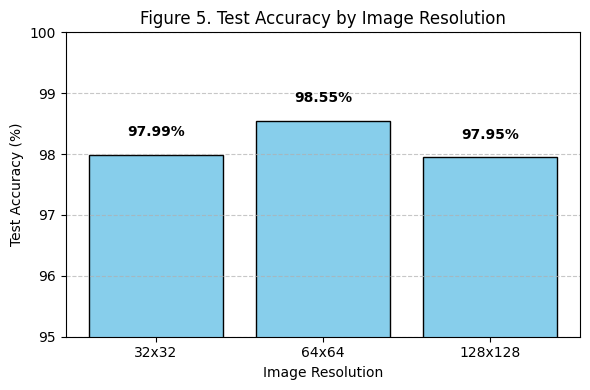

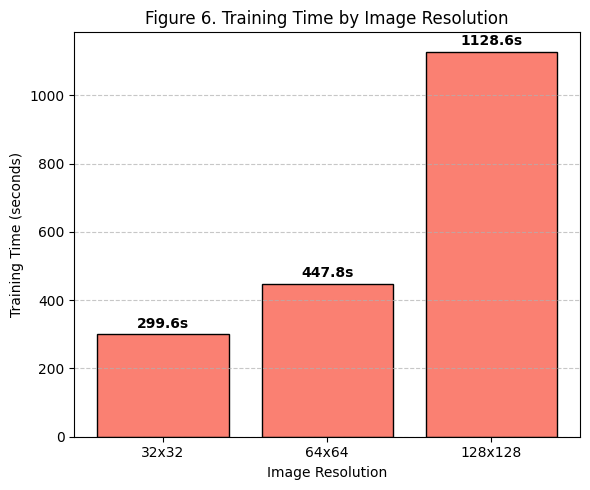

In [ ]:
# Ensure the output folder exists
output_dir = 'Image Resolution'
os.makedirs(output_dir, exist_ok=True)

resolutions = ['32x32', '64x64', '128x128']
test_accuracies = [0.9799, 0.9855, 0.9795]
training_times = [299.65, 447.78, 1128.64]

# Figure 5: Test Accuracy by Image Resolution
plt.figure(figsize=(6, 4))
plt.bar(resolutions, [acc * 100 for acc in test_accuracies], color='skyblue', edgecolor='black')
plt.title('Figure 5. Test Accuracy by Image Resolution')
plt.xlabel('Image Resolution')
plt.ylabel('Test Accuracy (%)')
plt.ylim(95, 100)
for i, v in enumerate(test_accuracies):
    plt.text(i, (v * 100) + 0.3, f"{v*100:.2f}%", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'test_accuracy.png'))
plt.show()

# Figure 6: Training Time by Image Resolution
plt.figure(figsize=(6, 5))
plt.bar(resolutions, training_times, color='salmon', edgecolor='black')
plt.title('Figure 6. Training Time by Image Resolution')
plt.xlabel('Image Resolution')
plt.ylabel('Training Time (seconds)')
for i, v in enumerate(training_times):
    plt.text(i, v + 20, f"{v:.1f}s", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'training_time.png'))
plt.show()

## Model Eval & Classification Metrics

In [ ]:
# Ensure the output folder exists
output_dir = 'Metrics'
os.makedirs(output_dir, exist_ok=True)

# Load the saved model weights/architecture
loaded_model = tf.keras.models.load_model("Models/rice_model.keras")

# Evaluate directly on the test set
test_loss, test_acc = loaded_model.evaluate(test_ds, verbose=1)
print(f"Loaded Model Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

# Collect test targets and predictions for the 64x64 model
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = loaded_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Figure 7: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Figure 7: Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.savefig(os.path.join(output_dir, 'confusion_matrix.png'))
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=CLASSES))

## Predication Visualizations

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure the output folder exists
output_dir = 'Prediction'
os.makedirs(output_dir, exist_ok=True)

for images, labels in test_ds.take(1):
    preds = loaded_model.predict(images, verbose=0)
    pred_labels = np.argmax(preds, axis=1)

    # Helper function to plot and center n images
    def plot_centered_images(indices, title, filename):
        n_imgs = min(len(indices), 5)
        if n_imgs == 0:
            print(f"No samples to display for {title}")
            return

        fig = plt.figure(figsize=(10, 3))

        # Calculate starting offset to center subplots across 5 columns
        start_col = (5 - n_imgs) / 2

        for i, idx in enumerate(indices[:n_imgs]):
            # Position each subplot centered dynamically
            ax = fig.add_subplot(1, n_imgs, i + 1)
            ax.imshow(images[idx].numpy())
            ax.set_title(f"P: {CLASSES[pred_labels[idx]]}\nA: {CLASSES[labels[idx]]}")
            ax.axis('off')

        plt.suptitle(title)
        plt.tight_layout()
        plt.savefig(os.path.join(output_dir, filename))
        plt.show()

    # Figure 8: Correct Predictions
    correct_indices = np.where(pred_labels == labels.numpy())[0]
    plot_centered_images(correct_indices, 'Figure 8. Correct Predictions', 'correct_predictions.png')

    # Figure 9: Incorrect Predictions
    incorrect_indices = np.where(pred_labels != labels.numpy())[0]
    if len(incorrect_indices) > 0:
        plot_centered_images(incorrect_indices, 'Figure 9. Incorrect Predictions', 'incorrect_predictions.png')
    else:
        print("No incorrect predictions found in this batch!")